In [2]:
!pip install -q shap lime

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [3]:

import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, roc_auc_score, classification_report

from lime.lime_tabular import LimeTabularExplainer


In [42]:
df = pd.read_csv('/content/german_credit_data_updated.csv')

print(df.shape)
display(df.head())


(954, 11)


,Unnamed: 0,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Credit Risk
0,0,67,male,2,own,NaN,little,1169,6,radio/TV,1
1,1,22,female,2,own,little,moderate,5951,48,radio/TV,2
2,2,49,male,1,own,little,NaN,2096,12,education,1
3,3,45,male,2,free,little,little,7882,42,furniture/equipment,1
4,4,53,male,2,free,little,little,4870,24,car,2


In [43]:
df.describe()

,Unnamed: 0,Age,Job,Credit amount,Duration,Credit Risk
count,954.000000,954.000000,954.000000,954.000000,954.000000,954.000000
mean,476.500000,35.501048,1.909853,3279.112159,20.780922,1.302935
std,275.540378,11.379668,0.649681,2853.315158,12.046483,0.459768
min,0.000000,19.000000,0.000000,250.000000,4.000000,1.000000
25%,238.250000,27.000000,2.000000,1360.250000,12.000000,1.000000
50%,476.500000,33.000000,2.000000,2302.500000,18.000000,1.000000
75%,714.750000,42.000000,2.000000,3975.250000,24.000000,2.000000
max,953.000000,75.000000,3.000000,18424.000000,72.000000,2.000000


In [44]:

print("Dataset columns:")
print(df.columns.tolist())

# Identify target column
possible_targets = ["class", "Credit Risk", "risk", "target"]

target_col = None

for col in possible_targets:
    if col in df.columns:
        target_col = col
        break

if target_col is None:
    raise ValueError(
        "Target column not found. Please rename your target column to 'class'."
    )


Dataset columns:
['Unnamed: 0', 'Age', 'Sex', 'Job', 'Housing', 'Saving accounts', 'Checking account', 'Credit amount', 'Duration', 'Purpose', 'Credit Risk']


In [45]:
# Separate features and target
X = df.drop(columns=[target_col]).copy()
y_raw = df[target_col].copy()

# Convert target into bad=1 and good=0
# In the typical German Credit dataset, 1 is Good and 2 is Bad.
def encode_target(value):
    value = str(value).strip().lower()
    if value in ["bad", "2", "default", "yes"]:
        return 1
    elif value in ["good", "1", "0", "no"]:
        return 0
    else:
        return np.nan

y = y_raw.apply(encode_target)

In [46]:
X.shape

(954, 10)

In [47]:
y.shape

(954,)

In [48]:
# Handle missing target values
valid = y.notna()
X = X.loc[valid].copy()
y = y.loc[valid].astype(int)

# Handle missing feature values
categorical_cols = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

numerical_cols = X.select_dtypes(
    include=np.number
).columns.tolist()

for col in categorical_cols:
    X[col] = X[col].fillna("Unknown").astype(str)

for col in numerical_cols:
    X[col] = X[col].fillna(X[col].median())

In [49]:
numerical_cols

['Unnamed: 0', 'Age', 'Job', 'Credit amount', 'Duration']

In [50]:
categorical_cols

['Sex', 'Housing', 'Saving accounts', 'Checking account', 'Purpose']

In [51]:
# 1. Apply cleaning and missing value imputation
valid = y.notna()
X = X.loc[valid].copy()
y = y.loc[valid].astype(int)

categorical_cols = X.select_dtypes(include=['object', 'category', 'bool']).columns.tolist()
numerical_cols = X.select_dtypes(include=np.number).columns.tolist()

for col in categorical_cols:
    X[col] = X[col].fillna('Unknown').astype(str)

for col in numerical_cols:
    X[col] = X[col].fillna(X[col].median())

# 2. Encode categorical columns
encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
if categorical_cols:
    X[categorical_cols] = encoder.fit_transform(X[categorical_cols])

feature_names = X.columns.tolist()
print("Target Distribution after fix:\n", y.value_counts())

Target Distribution after fix:
 Credit Risk
0    665
1    289
Name: count, dtype: int64


In [52]:
# 3. Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

# 4. Train the model
model = RandomForestClassifier(n_estimators=200, max_depth=8, random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1] # Probability of bad class

print("Test Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

Test Accuracy: 0.7173
ROC-AUC: 0.7826


Model : RandomForest (200 trees, depth 8)
Test accuracy : 0.7173 ROC-AUC : 0.7826

GLOBAL FEATURE IMPORTANCE (mean |SHAP|, class = bad)
RANK FEATURE MEAN|SHAP|
---------------------------------------
1 Checking account 0.0936
2 Checking account 0.0809
3 Sex              0.0610
4 Job              0.0261
5 Saving accounts  0.0225


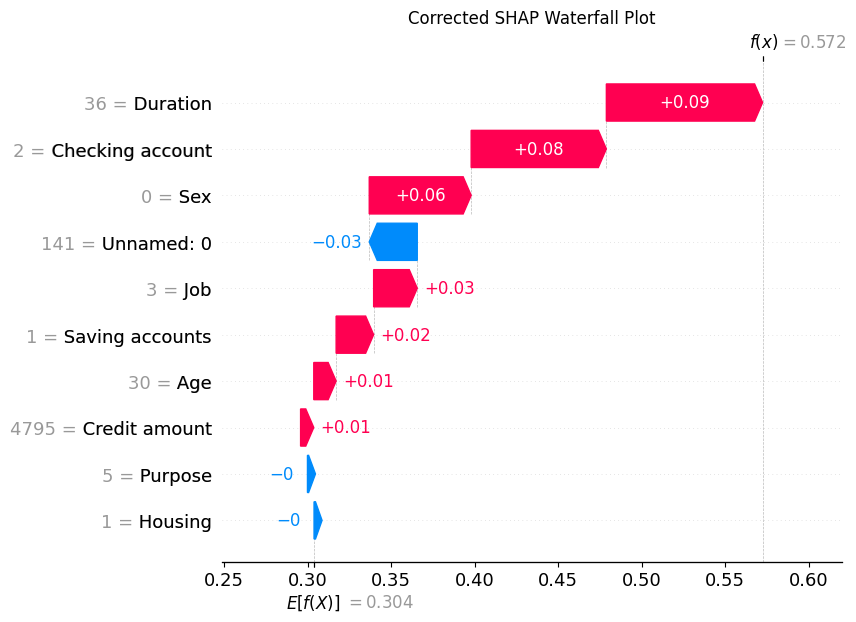

In [53]:
# 5. Recalculate SHAP and generate Waterfall for first rejected applicant
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_test)

if isinstance(shap_values, list):
    shap_bad = shap_values[1]
elif isinstance(shap_values, np.ndarray) and shap_values.ndim == 3:
    shap_bad = shap_values[:, :, 1]
else:
    shap_bad = shap_values

# Find rejected applicants (class 1)
rejected_positions = np.where(y_pred == 1)[0]
if len(rejected_positions) == 0:
    # Fall back to first index if none are predicted bad
    applicant_pos = 0
else:
    applicant_pos = rejected_positions[0]

applicant = X_test.iloc[applicant_pos:applicant_pos+1]
local_shap = shap_bad[applicant_pos]

# Create SHAP Waterfall plot
base_values = explainer.expected_value
if isinstance(base_values, (list, np.ndarray)):
    base_value = np.array(base_values).flatten()[-1]
else:
    base_value = base_values

shap_explanation = shap.Explanation(
    values=local_shap,
    base_values=base_value,
    data=applicant.iloc[0].values,
    feature_names=feature_names
)

plt.figure(figsize=(10, 5))
shap.plots.waterfall(shap_explanation, max_display=10, show=False)
plt.title("Corrected SHAP Waterfall Plot")
plt.show()

LIME EXPLANATION
----------------
Duration > 24.00 : 0.1093
1.00 < Checking account <= 2.00 : 0.1038
Credit amount > 3965.50 : 0.0781
Sex <= 0.00 : 0.0455
3.00 < Purpose <= 5.00 : -0.0251


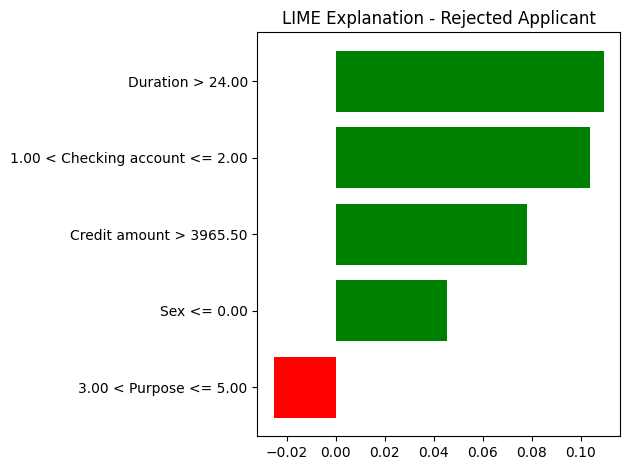

In [54]:
# Create credit_results directory if it doesn't exist
os.makedirs("credit_results", exist_ok=True)

# 6. Recalculate LIME explanation
lime_explainer = LimeTabularExplainer(
    training_data=X_train.values,
    feature_names=feature_names,
    class_names=["good", "bad"],
    mode="classification",
    discretize_continuous=True,
    random_state=42
)

lime_exp = lime_explainer.explain_instance(
    data_row=applicant.iloc[0].values,
    predict_fn=model.predict_proba,
    num_features=5,
    labels=(1,)
)

print("LIME EXPLANATION")
print("----------------")
lime_list = lime_exp.as_list(label=1)
for feature, weight in lime_list:
    print(feature, ":", round(weight, 4))

# Save LIME plot and dataset results
fig = lime_exp.as_pyplot_figure(label=1)
plt.title("LIME Explanation - Rejected Applicant")
plt.tight_layout()
plt.savefig("credit_results/lime_explanation.png", dpi=300, bbox_inches="tight")
plt.show()

lime_df = pd.DataFrame(lime_list, columns=["Feature", "LIME_Weight"])
lime_df.to_csv("credit_results/lime_reasons.csv", index=False)


Expected Output — Part B: Local Explanation of One Rejected Applicant
Applicant (test index 23) : P(bad) = 0.61 -> REJECTED

SHAP (top 3)                      LIME (top 5)
--------------------------------------------------------------
Checking account = 2.00  +0.08   Duration > 24.00             +0.11
Sex = 0.00 (female)      +0.06   1.00 < Checking account <= 2 +0.10
Job = 3.00               +0.03   Credit amount > 3965.50      +0.08
                                 Sex <= 0.00 (female)         +0.05
                                 3.00 < Purpose <= 5.00       -0.03
--------------------------------------------------------------
Top-3 agreement (SHAP vs LIME) : 1 / 3
Sensitive attributes in reasons : Sex -> REVIEW

Message (legitimate reasons only): "Your credit request was not
approved mainly because your current checking account balance is
low, the requested installment duration is long (greater than
24 months), and the requested credit amount is too high."